In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

def load_dataset(filename, cols=None, sheet_name=0):
    BASE_DIR = Path(r"C:\work\Port_Cast_Final")
    FILE_PATH = BASE_DIR / "1.Rawdata_EDA" / "Data" / filename

    return pd.read_excel(
        FILE_PATH,
        sheet_name=sheet_name,
        usecols=cols
    )

In [2]:
df = load_dataset("port_raw.xlsx")

In [3]:
df.head()

,선박키,입항연도,적재톤수,환적톤수,위험물톤수,총톤수,선박종류명,선박명,출항예정일시,입항일시,...,터미널_출항시각출처,터미널_접안시간,터미널_시간당처리량,터미널_접안시간계산상태,터미널_Shift비율,출항시간차이_분,부산항_입항출항시간차_분,터미널_접안출항시간차_분,접안_부산항입항시간차_분,시간검증상태
0,A8SI6,2020,60500.0,3569.0,0.0,114044,풀컨테이너선,ZIM ANTWERP,2020-01-23 6:00,2020-01-22 12:00,...,예정 출항 대체,21.666667,79.292308,계산완료,0.065288,50,1260,1300,10,정상
1,9713349,2020,50382.0,13581.0,346.0,113042,풀컨테이너선,MOL BEAUTY,2020-01-22 6:00,2020-01-21 3:10,...,예정 출항 대체,35.950000,80.806676,계산완료,0.050964,0,2162,2157,5,정상
2,A8OJ4,2020,6654.0,4802.0,75.0,9610,풀컨테이너선,AS LEONA,2020-01-20 8:00,2020-01-19 14:00,...,예정 출항 대체,18.083333,49.050691,계산완료,0.000000,20,1060,1085,-5,정상
3,DDYZ2,2020,29540.0,4321.0,0.0,82794,풀컨테이너선,PRESIDENT KENNEDY,2020-01-20 14:00,2020-01-19 22:00,...,예정 출항 대체,21.666667,56.076923,계산완료,0.129032,0,1320,1300,20,정상
4,SWWC,2020,80714.0,5151.0,0.0,109149,풀컨테이너선,COSCO YANTIAN,2020-01-21 7:00,2020-01-20 15:00,...,예정 출항 대체,16.000000,81.937500,계산완료,0.003042,0,960,960,0,정상


In [39]:
df.shape

(36844, 35)

In [40]:
df.columns

Index(['선박키', '입항연도', '적재톤수', '환적톤수', '위험물톤수', '총톤수', '선박종류명', '선박명', '출항예정일시',
       '입항일시', '출항일시', '양하톤수', '터미널_선석', '터미널_선사', '터미널', '터미널_양하수량',
       '터미널_선적수량', '터미널_Shift수량', '터미널_출항예정일시', '터미널_출항일시', '터미널_접안일시',
       '터미널_접안예정일시', '터미널_순수물동량', '터미널_총작업량', '터미널_계산용출항일시', '터미널_출항시각출처',
       '터미널_접안시간', '터미널_시간당처리량', '터미널_접안시간계산상태', '터미널_Shift비율', '출항시간차이_분',
       '부산항_입항출항시간차_분', '터미널_접안출항시간차_분', '접안_부산항입항시간차_분', '시간검증상태'],
      dtype='str')

In [41]:
# 총톤수로 선박크기 구분

# 1. 총톤수를 숫자로 변환
df['총톤수'] = pd.to_numeric(
    df['총톤수'].astype(str).str.replace(',', '', regex=False).str.strip()
)

#2. 선박 크기 구분
def gross_tonnage_class(tonnage):
    if tonnage <= 2000:
        return 'very_small'
    elif tonnage <= 5000:
        return 'small'
    elif tonnage <= 10000:
        return 'small_medium'
    elif tonnage <= 20000:
        return 'medium'
    elif tonnage <= 50000:
        return 'medium_large'
    elif tonnage <= 100000:
        return 'large'
    elif tonnage <= 150000:
        return 'very_large'
    else:
        return 'ultra_large'



In [42]:
# 3. df를 복사하고 선박크기 열 추가
df1 = df.copy()

df1['총톤수'] = pd.to_numeric(
    df1['총톤수'].astype(str).str.replace(',', '', regex=False).str.strip()
)

df1['선박크기'] = df1['총톤수'].apply(gross_tonnage_class)

# 4. 결과 확인
df1[['총톤수', '선박크기']]

,총톤수,선박크기
0,114044,very_large
1,113042,very_large
2,9610,small_medium
3,82794,large
4,109149,very_large
...,...,...
36839,141716,very_large
36840,116295,very_large
36841,99995,large
36842,3981,small


재항시간(출항-입항)과 선박크기간의 관계

In [43]:
#1. 재항시간을 숫자로 변환
df1['부산항_입항출항시간차_분'] = pd.to_numeric(
    df1['부산항_입항출항시간차_분']
)

print(df1['부산항_입항출항시간차_분'].dtype)

int64


In [44]:
#2. 분 -> 시간으로 변환
df1['재항시간(시간)'] = (df1['부산항_입항출항시간차_분'] / 60).round(2)

df1[['부산항_입항출항시간차_분','재항시간(시간)']].head()

,부산항_입항출항시간차_분,재항시간(시간)
0,1260,21.00
1,2162,36.03
2,1060,17.67
3,1320,22.00
4,960,16.00


In [45]:
# 선박크기별 재항시간의 평균, 중앙값을 확인하기

#1. 선박 크기를 작은 순서대로 지정
size_order = [
    'very_small',
    'small',
    'small_medium',
    'medium',
    'medium_large',
    'large',
    'very_large',
    'ultra_large',
]

#2. 선박크기별 재항시간 요약
stay_summary = (
    df1.groupby('선박크기')['재항시간(시간)']
    .agg(['count','mean', 'median'])
    .reindex(size_order)
    .round(2)
)

# 3. 결과의 열 이름을 알아보기 쉽게 변경
stay_summary.columns = ['건수','평균_시간', '중앙값_시간']

# 4. 결과확인
display(stay_summary)

,건수,평균_시간,중앙값_시간
선박크기,,,
very_small,130,24.09,13.54
small,993,24.86,15.90
small_medium,13638,23.84,18.00
medium,4601,26.19,20.00
medium_large,5318,25.81,19.48
large,6625,26.60,23.95
very_large,3634,31.85,29.92
ultra_large,1905,37.37,34.85


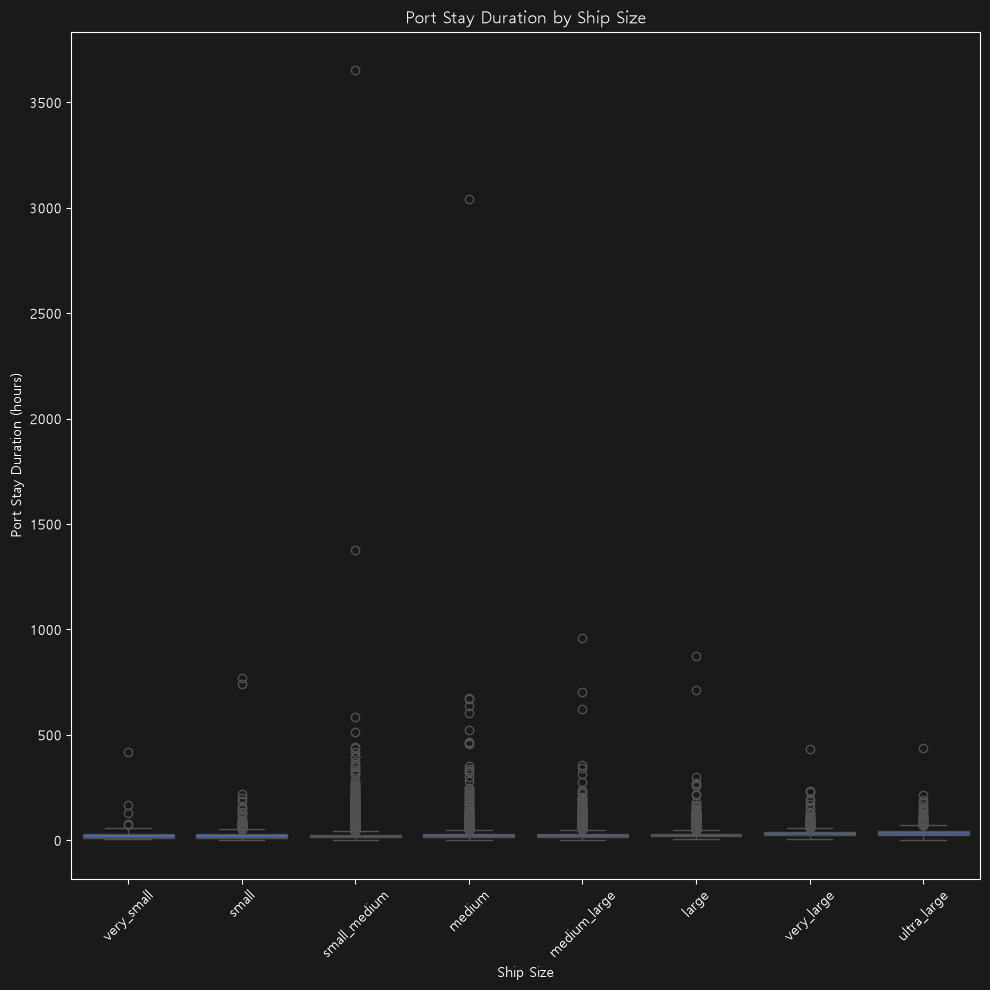

In [46]:
# 각 선박 크기별 재항시간 비교 (박스플롯)

plt.figure(figsize=(10, 10))

sns.boxplot(
    data = df1,
    x = '선박크기',
    y = '재항시간(시간)',
    order = size_order,
)

# 제목과 축 이름 설정
plt.title('Port Stay Duration by Ship Size')
plt.xlabel('Ship Size')
plt.ylabel('Port Stay Duration (hours)')

# 가로축 글자가 겹치지 않도록 회전
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- 긴 재항시간때문에 상자가 눌려보임.
- 이상치의 점을 숨겨서 다시 확인필요

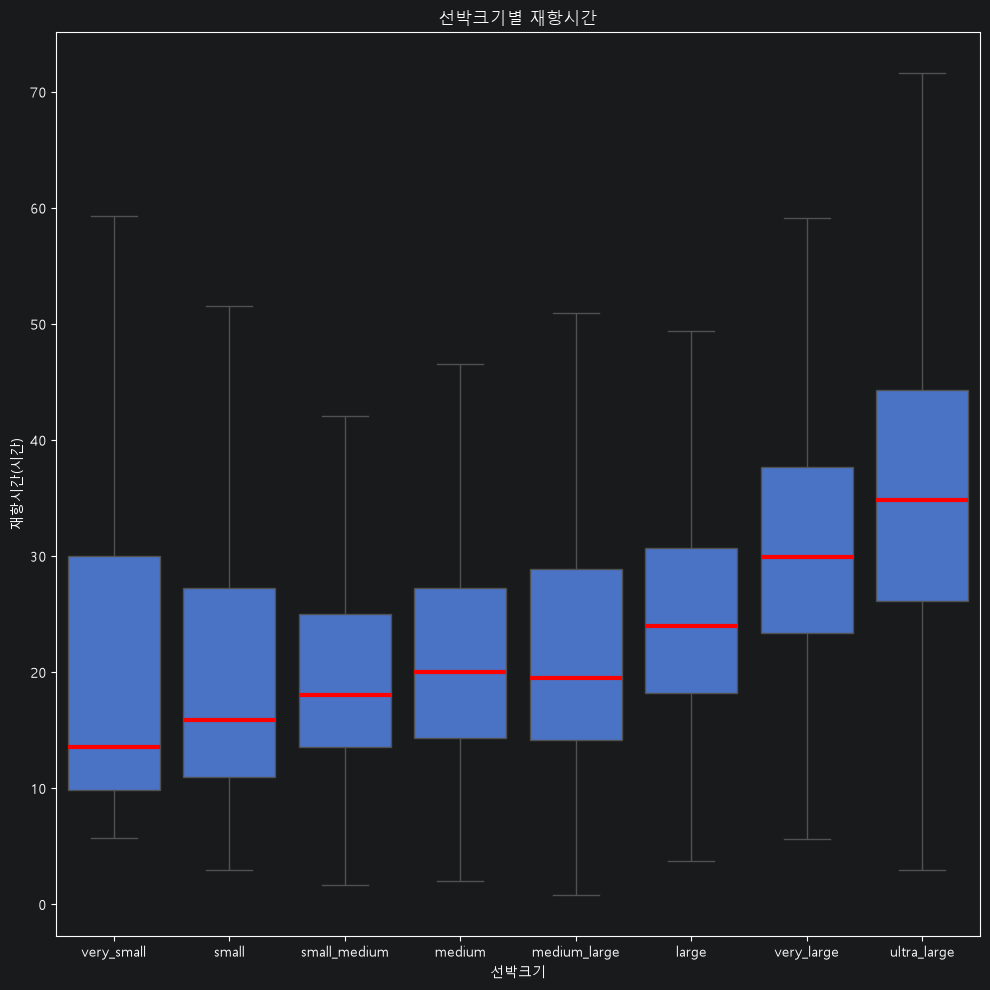

In [47]:
plt.figure(figsize=(10, 10))

sns.boxplot(
    data = df1,
    x = '선박크기',
    y = '재항시간(시간)',
    order = size_order,
    showfliers=False,
    medianprops={'color': 'red', 'linewidth': 3})


plt.title('선박크기별 재항시간')
plt.xlabel('선박크기')
plt.ylabel('재항시간(시간)')

plt.xticks()
plt.tight_layout()
plt.show()



In [48]:
# 특정 크기의 선박의 재항시간 분포 확인

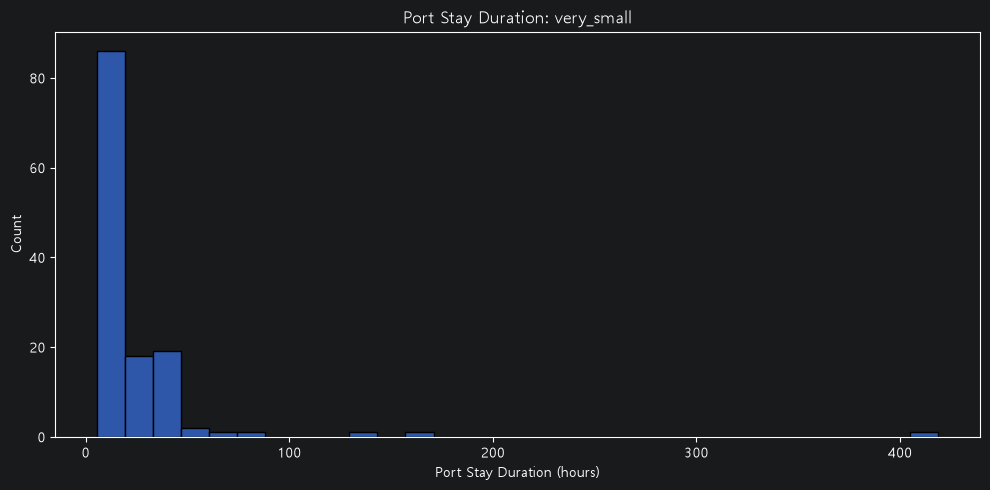

In [49]:
# very_small
# 1. 확인할 선박 크기를 지정합니다.
selected_size = 'very_small'

# 2. 해당 크기의 선박만 선택합니다.
selected_df = df1[df1['선박크기'] == selected_size]

# 3. 재항시간 히스토그램을 그립니다.
plt.figure(figsize=(10, 5))

sns.histplot(
    data=selected_df,
    x='재항시간(시간)',
    bins=30
)

plt.title(f'Port Stay Duration: {selected_size}')
plt.xlabel('Port Stay Duration (hours)')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

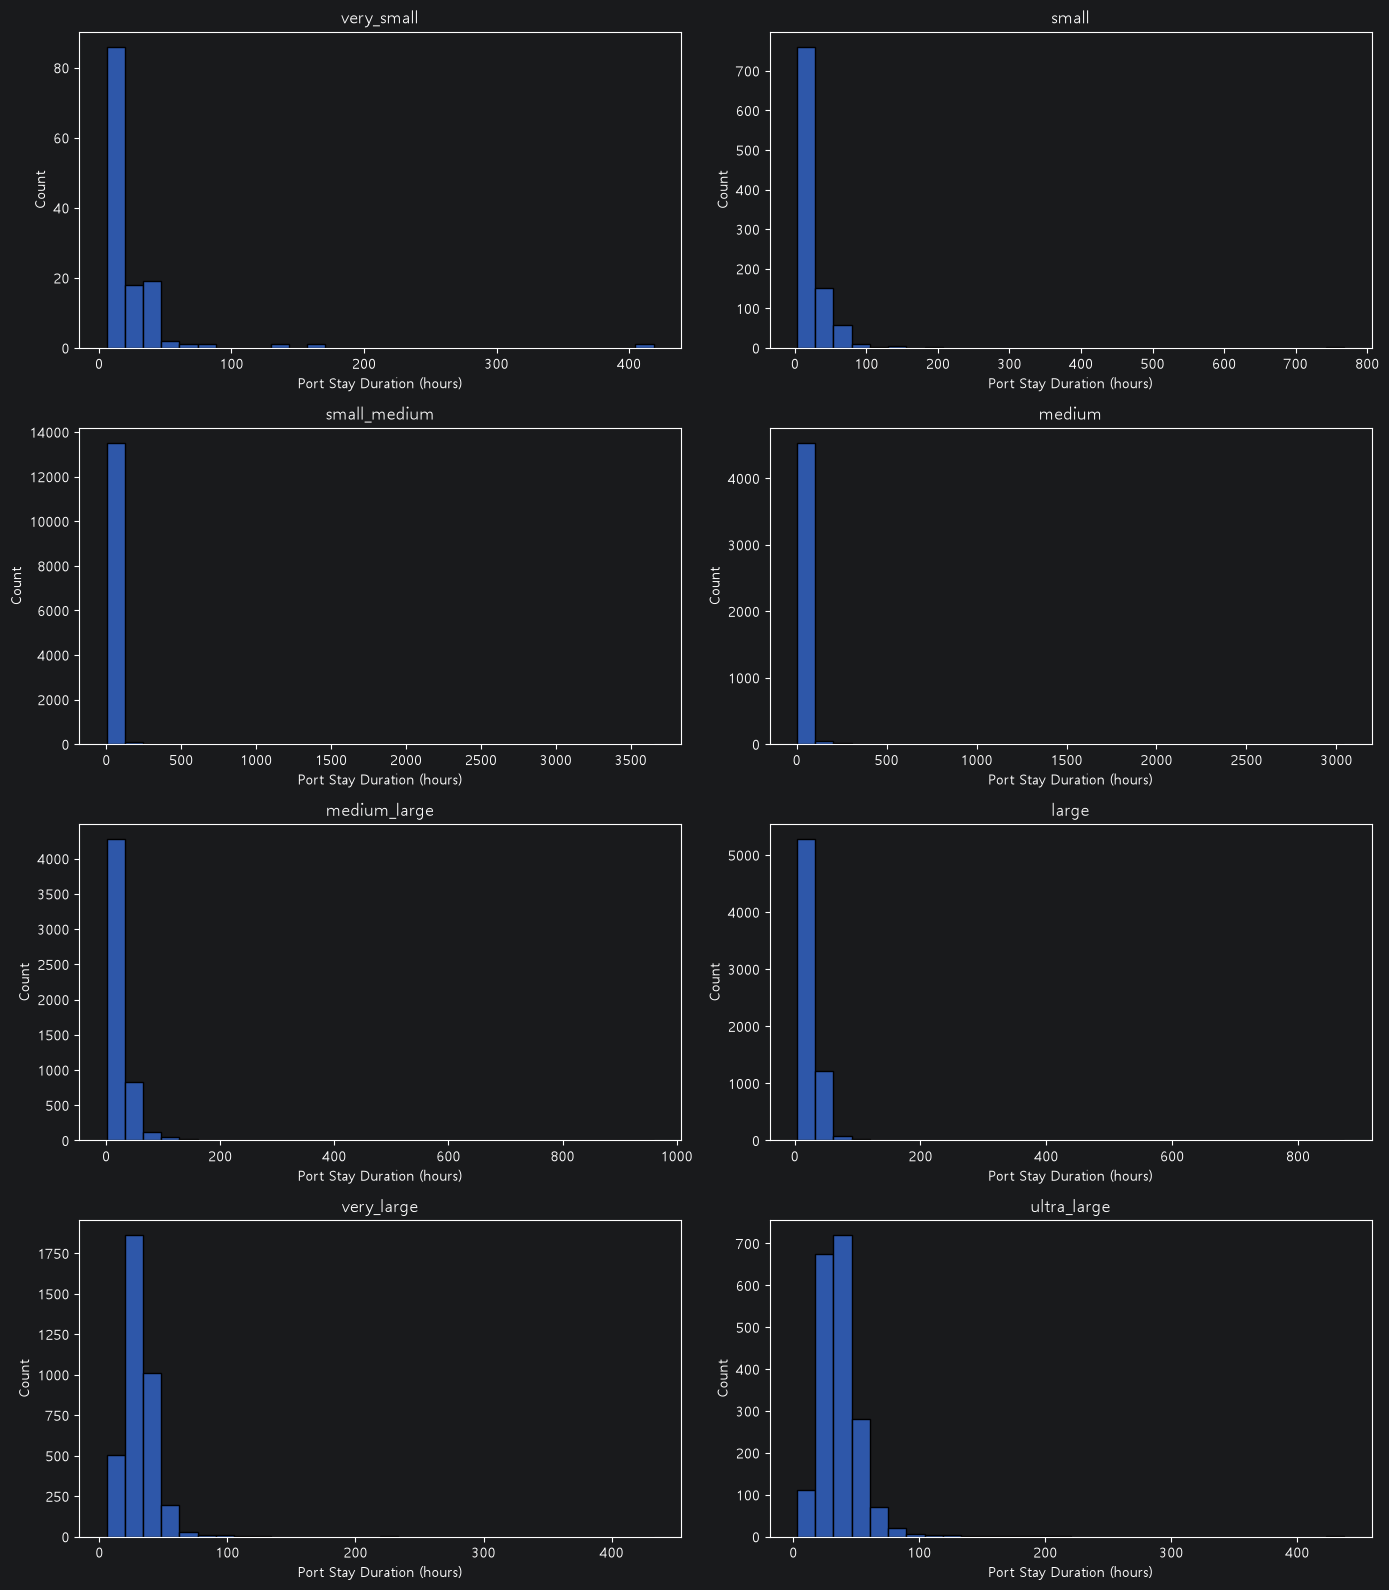

In [50]:

# 2. 4행 2열의 그래프 공간을 만듭니다.
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

# 3. 그래프 공간을 순서대로 사용할 수 있게 펼칩니다.
axes = axes.flatten()

# 4. 선박크기별로 히스토그램을 그립니다.
for i, size in enumerate(size_order):
    selected_df = df1[df1['선박크기'] == size]

    sns.histplot(
        data=selected_df,
        x='재항시간(시간)',
        bins=30,
        ax=axes[i]
    )

    axes[i].set_title(size)
    axes[i].set_xlabel('Port Stay Duration (hours)')
    axes[i].set_ylabel('Count')

# 5. 그래프끼리 겹치지 않도록 간격을 조정합니다.
plt.tight_layout()
plt.show()